## Laboratorio tabla hash





In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema
Una tienda necesita mejorar la forma en que consulta los productos de su inventario.
Actualmente tiene muchos productos registrados y recorrer toda una lista cada vez que necesita buscar uno resulta poco eficiente.
Para solucionar este problema se deberá implementar una Tabla Hash, utilizando como llave el código numérico del producto.

Cada producto tendrá:

Código-Nombre-Precio-Cantidad-disponible

## 2) Requerimientos

REQUERIMIENTOS FUNCIONALES

- RF01: CREACIÓN DE LA TABLA HASH — El sistema debe permitir al usuario indicar el tamaño m y crear una tabla hash con m posiciones, todas vacías al inicio.

- RF02: FUNCIÓN HASH — El sistema debe calcular la posición de cada producto usando h(código) = código % m, donde el código numérico del producto es la llave.

- RF03: REGISTRO DE PRODUCTOS — El sistema debe permitir registrar n productos con código, nombre, precio y cantidad disponible, sin aceptar dos productos con el mismo código.

- RF04: MANEJO DE COLISIONES — El sistema debe resolver las colisiones por encadenamiento, de modo que varios productos con el mismo índice queden guardados en la misma posición.

- RF05: BÚSQUEDA DE PRODUCTOS — El sistema debe buscar un producto por su código accediendo directamente a la posición calculada con la función hash, sin recorrer toda la tabla.

- RF06: ELIMINACIÓN DE PRODUCTOS — El sistema debe eliminar únicamente el producto cuyo código se indique, buscándolo en su posición, y avisar si el código no existe.

- RF07: ACTUALIZACIÓN DE INVENTARIO — El sistema debe permitir buscar un producto por su código y modificar su cantidad disponible.

- RF08: VISUALIZACIÓN DE LA TABLA — El sistema debe mostrar todas las posiciones de la tabla, indicando las vacías y listando todos los productos de las posiciones con colisiones.

REQUERIMIENTOS NO FUNCIONALES

- RNF01: EFICIENCIA — La búsqueda, la eliminación y la actualización de un producto deben usar primero la función hash para ir directo a su posición, de modo que cada operación se ejecute en tiempo promedio O(1 + α), donde α = n / m, sin recorrer toda la tabla.

- RNF02: MANTENIBILIDAD — El código debe estar dividido en funciones para que sea fácil de entender y modificar.

- RNF03: ENCADENAMIENTO PARA COLISIONES — Cada posición de la tabla debe guardar una lista de productos, para que las colisiones se resuelvan por encadenamiento y ningún producto se pierda ni se escriba dos veces.

- RNF04: IMPLEMENTACIÓN MANUAL DE LA TABLA HASH — La tabla hash debe construirse a mano, usando una lista de m posiciones y la función h(código) = código % m.

- RNF05: LENGUAJE — Se programa en Python porque es un lenguaje fácil de comprender, lo que permite mayor aprendizaje y entendimiento.


## 3) Historias de usuario

- HU01: REGISTRO DE PRODUCTOS: Como encargado de la tienda quiero registrar productos con su código, nombre, precio y cantidad, para tenerlos guardados en el inventario.

Criterios de aceptación:
- Cada producto se guarda en la posición que resulta de código % m.
- Si el código ya existe, el sistema avisa y no lo registra.
- Si dos productos caen en la misma posición, ambos quedan guardados.


- HU02: CONSULTA DE LA TABLA: Como encargado de la tienda quiero ver el contenido completo de la tabla hash, para conocer cómo está organizado el inventario y ver las colisiones.

Criterios de aceptación:
- El sistema muestra todas las posiciones, de 0 a m-1.
- Las posiciones sin productos aparecen como “Vacío”.
- Las posiciones con colisión muestran todos sus productos, sin repetidos.


- HU03: BÚSQUEDA DE UN PRODUCTO: Como encargado de la tienda quiero consultar un producto por su código, para ver su nombre, precio y cantidad disponible de forma rápida.

Criterios de aceptación:
- La búsqueda calcula el índice con la función hash y solo revisa esa posición.
- Si el producto existe, se muestran todos sus datos.
- Si no existe, se muestra “El producto no está registrado.”


- HU04: ELIMINACIÓN DE UN PRODUCTO: Como encargado de la tienda quiero eliminar un producto por su código, para quitar del inventario lo que ya no manejo.

Criterios de aceptación:
- Solo se elimina el producto indicado; los demás de la misma posición se conservan.
- Si el código no existe, se muestra “No se encontró el producto.”


- HU05: ACTUALIZACIÓN DEL INVENTARIO: Como encargado de la tienda quiero modificar la cantidad disponible de un producto, para mantener el stock al día.

Criterios de aceptación:
- El producto se busca usando la tabla hash.
- Se muestra el mensaje “Inventario actualizado correctamente.” con el nombre y  la nueva cantidad.
- Si el código no existe, el sistema avisa y no modifica nada.

## 4) Diagramas de Flujo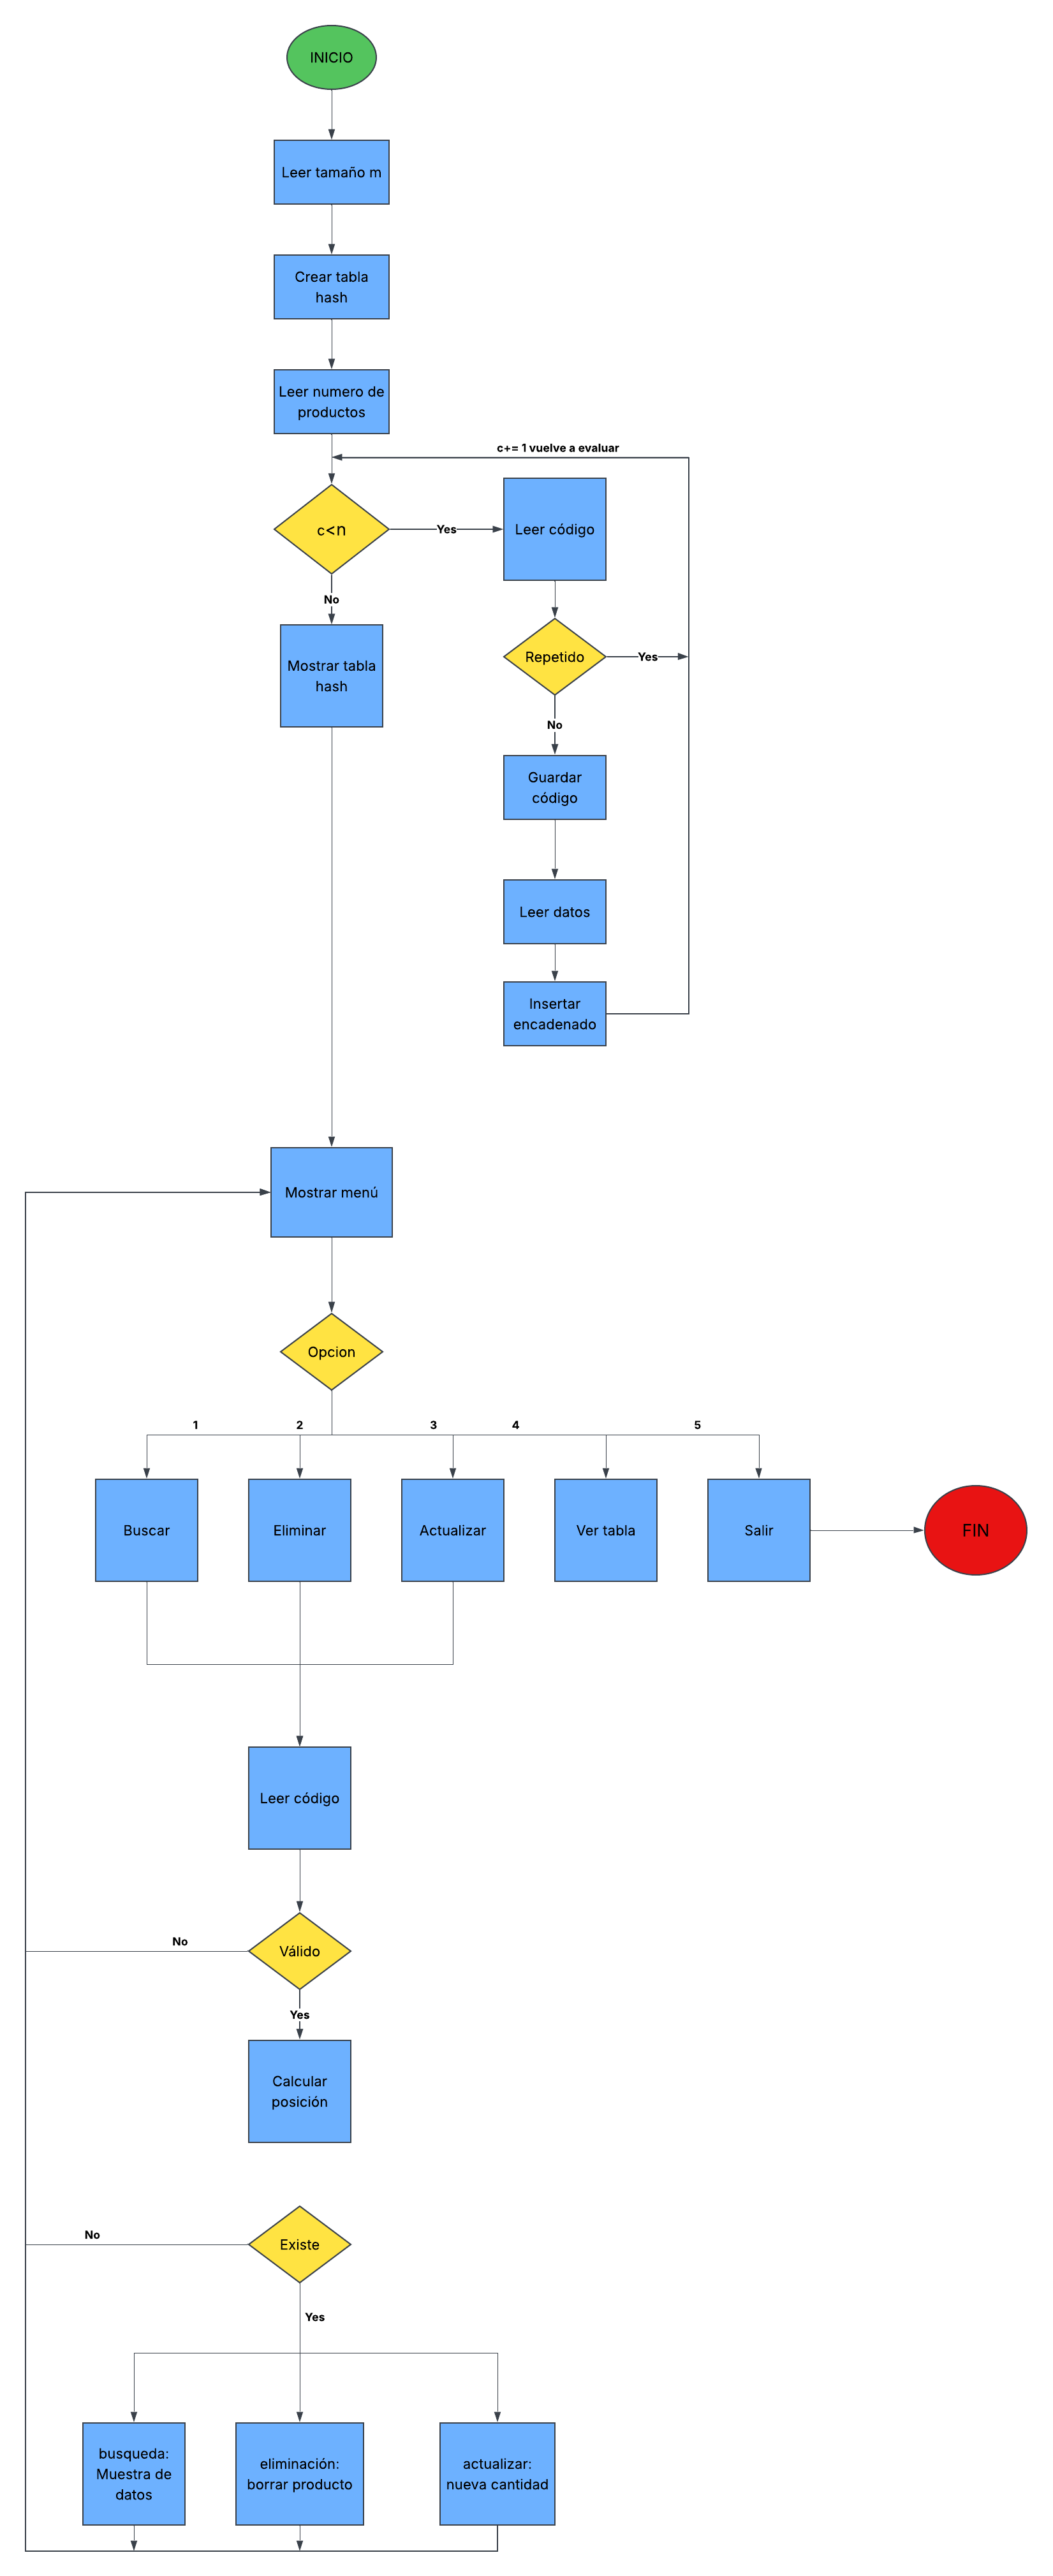

### 5) Análisis de complejidad
-Mejor caso: T(n)= O(1)
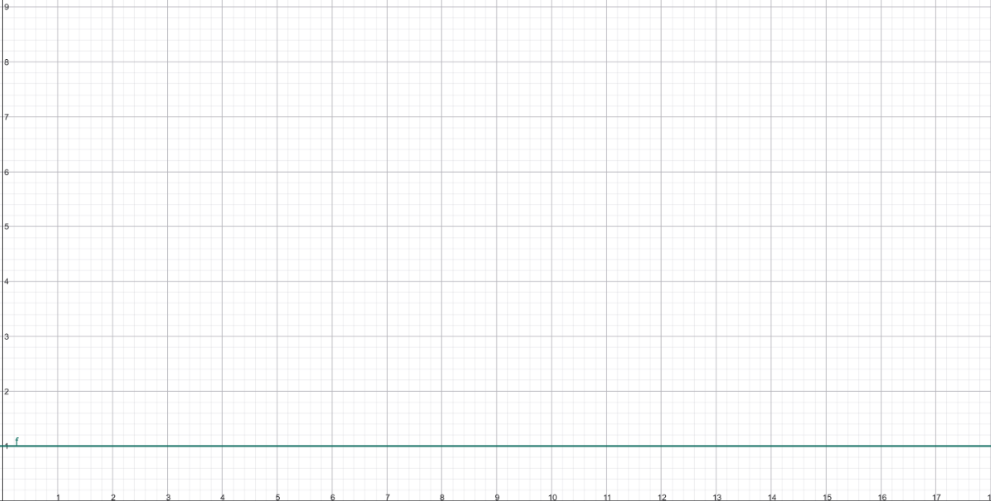
  


Por qué: el índice se calcula con código % m, que es una sola operación. Si los productos están bien repartidos, cada posición tiene muy pocos productos (0 o 1), así que al buscar, insertar, eliminar o actualizar se revisa a lo mucho un elemento.




-Peor caso:T(n)=O(n)
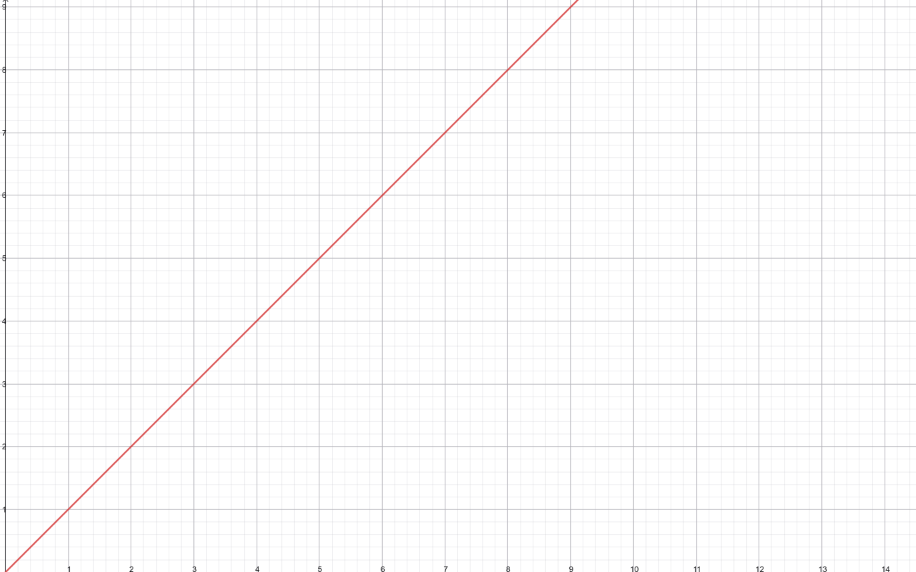



Por qué: ocurre cuando todos los códigos dan el mismo residuo al dividir por m. Entonces todos los productos quedan encadenados en una sola posición y hay que recorrer esa cadena completa, hasta n productos. En esa situación la tabla hash se comporta como una lista simple.

## 6) Código funcional **[15 pts]**


In [ ]:
def val_cod(a):
    try:
        val = int(a)
        if (val < 100) or (val > 999):
            raise ValueError
        return val, False
    except ValueError:
        print("\nDato invalido, por favor asegurese de ingresar solo: \nNumeros enteros de tres digitos\nNumeros positivos\nNo dejar el campo vacio\nNo ingresar letras ni simbolos\nIntroducir un solo numero\nNo usar espacios, comas o cualquier otro caracter\n")
        return 0, True

def val_num(a):
    try:
        val = int(a)
        if val < 0:
            raise ValueError
        return val, False
    except ValueError:
        print("\nDato invalido, por favor asegurese de ingresar solo: \nNumeros enteros \nNumeros positivos \nNo dejar el campo vacio\nNo ingresar letras ni simbolos\nIntroducir un solo numero\nNo usar espacios, comas o cualquier otro caracter\n")
        return 0, True

def busq(hash_dict, m):
    cod_input = input("Ingrese el código del producto a buscar: ")
    cod, err = val_cod(cod_input)
    if err: return
    key = cod % m
    lista_colisiones = hash_dict[key]

    for producto in lista_colisiones:
        if producto[0] == cod:
            print(f"Producto encontrado\nCódigo: {producto[0]} Nombre: {producto[1]} Precio: ${producto[2]} Cantidad disponible: {producto[3]}")
            return
    print("El producto no está registrado.")

def elim(hash_dict, m):
    cod_input = input("Código del producto que desea eliminar: ")
    cod, err = val_cod(cod_input)
    if err: return
    key = cod % m
    lista_colisiones = hash_dict[key]

    for i, producto in enumerate(lista_colisiones):
        if producto[0] == cod:
            del lista_colisiones[i]
            print("Producto eliminado correctamente.")
            return
    print("No se encontró el producto.")

def actua(hash_dict, m):
    cod_input = input("Ingrese el código del producto a actualizar: ")
    cod, err = val_cod(cod_input)
    if err: return
    key = cod % m
    lista_colisiones = hash_dict[key]

    for producto in lista_colisiones:
        if producto[0] == cod:
            print(f"Producto: {producto[1]} Cantidad actual: {producto[3]}")
            while True:
                nueva_cant = input("Nueva cantidad: ")
                cant, b = val_num(nueva_cant)
                if not b:
                    producto[3] = cant
                    print(f"Inventario actualizado correctamente. {producto[1]} - {cant} unidades")
                    return
    print("No se encontró el producto.")

def tabla_hash_mostrar(hash_dict, m):
    print("~~~TABLA HASH~~~")
    for i in range(m):
        lista_colisiones = hash_dict[i]
        if not lista_colisiones:
            print(f"{i} -> Vacío")
        else:
            items_str = "    ".join([f"{p[0]} - {p[1]}" for p in lista_colisiones])
            print(f"{i} -> {items_str}")

def main():
    codigos = []
    b = True
    while b == True:
        tamano = input("Ingrese el tamaño de la tabla hash: ")
        tamano, b = val_num(tamano)
    hash_dict = {i: [] for i in range(tamano)}
    print("\nBienvenido al programa")
    b_prod = True
    while b_prod == True:
        n_productos = input("¿Cuántos productos desea registrar?: ")
        n_productos, b_prod = val_num(n_productos)
    c = 0

    while c < n_productos:
        print(f"\n--- Registrando Producto {c + 1} ---")

        while True:
            cod = input("Ingrese un codigo de 3 digitos: ")
            cod, b = val_cod(cod)
            if b == False:
                break
        if cod in codigos:
            print("El codigo ya existe, por favor ingrese un codigo diferente")
            continue
        else:
            codigos.append(cod)
        prod = input("Ingrese el nombre del producto: ")

        while True:
            prec = input("Ingrese el precio del producto: ")
            prec, b = val_num(prec)
            if b == False:
                break

        while True:
            cant = input("Ingrese la cantidad del producto: ")
            cant, b = val_num(cant)
            if b == False:
                break
        c += 1
        cont = [cod, prod, prec, cant]
        key = cod % tamano
        hash_dict[key].append(cont)
        print("Producto agregado correctamente")

    tabla_hash_mostrar(hash_dict, tamano)

    while True:
        print("\n~~~ Menú ~~~")
        print("1. Buscar producto \n2. Eliminar producto \n3. Actualizar producto \n4. Ver tabla hash \n5. Salir")
        opc_input = input("Seleccione una opción: ")
        opc, b_opc = val_num(opc_input)
        if b_opc == True:
            continue
        if opc == 1:
            busq(hash_dict, tamano)
        elif opc == 2:
            elim(hash_dict, tamano)
        elif opc == 3:
            actua(hash_dict, tamano)
        elif opc == 4:
            tabla_hash_mostrar(hash_dict, tamano)
        elif opc == 5:
            print("Saliendo del programa...")
            break
        else:
            print("Opción no válida. Intente de nuevo.")

main()

Ingrese el tamaño de la tabla hash: 2

Bienvenido al programa
¿Cuántos productos desea registrar?: 3

--- Registrando Producto 1 ---
Ingrese un codigo de 3 digitos: 123
Ingrese el nombre del producto: asd
Ingrese el precio del producto: 1
Ingrese la cantidad del producto: 1
Producto agregado correctamente

--- Registrando Producto 2 ---
Ingrese un codigo de 3 digitos: 234
Ingrese el nombre del producto: sdf
Ingrese el precio del producto: 2
Ingrese la cantidad del producto: 2
Producto agregado correctamente

--- Registrando Producto 3 ---
Ingrese un codigo de 3 digitos: 345
Ingrese el nombre del producto: dfg
Ingrese el precio del producto: 3
Ingrese la cantidad del producto: 3
Producto agregado correctamente
~~~TABLA HASH~~~
0 -> 234 - sdf
1 -> 123 - asd    345 - dfg

~~~ Menú ~~~
1. Buscar producto 
2. Eliminar producto 
3. Actualizar producto 
4. Ver tabla hash 
5. Salir
Seleccione una opción: 1
Ingrese el código del producto a buscar: 123
Producto encontrado
Código: 123 Nombre: asd

## 7) Tests aplicados **[15 pts]**

In [ ]:
def busq(hash_dict, m, cod):
    key = cod % m
    lista_colisiones = hash_dict[key]

    for producto in lista_colisiones:
        if producto[0] == cod:
            print(f"Producto encontrado\nCódigo: {producto[0]} Nombre: {producto[1]} Precio: ${producto[2]} Cantidad disponible: {producto[3]}")
            return

    print("El producto no está registrado.")

def elim(hash_dict, m, cod):
    key = cod % m
    lista_colisiones = hash_dict[key]

    for i, producto in enumerate(lista_colisiones):
        if producto[0] == cod:
            del lista_colisiones[i]
            print("Producto eliminado correctamente.")
            return

    print("No se encontró el producto.")

def actua(hash_dict, m, cod, nueva_cant):
    key = cod % m
    lista_colisiones = hash_dict[key]

    for producto in lista_colisiones:
        if producto[0] == cod:
            print(f"Producto: {producto[1]} Cantidad actual: {producto[3]}")
            producto[3] = nueva_cant
            print(f"Inventario actualizado correctamente. {producto[1]} - {nueva_cant} unidades")
            return

    print("No se encontró el producto.")

def tabla_hash_mostrar(hash_dict, m):
    print(" ~~~!TABLA HASH~~~")

    for i in range(m):
        lista_colisiones = hash_dict[i]
        if not lista_colisiones:
            print(f"{i} -> Vacío")
        else:
            items_str = "    ".join([f"{p[0]} - {p[1]}" for p in lista_colisiones])
            print(f"{i} -> {items_str}")

def test(opc, cod=None, nueva_cant=None):
    tamano = 7
    hash_dict = {i: [] for i in range(tamano)}

    productos_prueba = [
        [101, "Arroz", 4500, 20],
        [108, "Huevos", 16000, 12],
        [115, "Azucar", 3500, 15],
        [205, "Leche", 3800, 15],
        [312, "Cafe", 12000, 10]
    ]

    for p in productos_prueba:
        key = p[0] % tamano
        hash_dict[key].append(p)

    print(f"\n--- INICIANDO PRUEBA OPCIÓN {opc} ---")

    if opc == 1:
        print(f"Probando Búsqueda con producto en colisión (Código {cod})...")
        busq(hash_dict, tamano, cod)

    elif opc == 2:
        print(f"Probando Eliminación con producto en colisión (Código {cod})...")
        elim(hash_dict, tamano, cod)
        print("\nRevisando la tabla después de eliminar (Nota como el 101 y 115 siguen intactos):")
        tabla_hash_mostrar(hash_dict, tamano)

    elif opc == 3:
        print(f"Probando Actualización con producto en colisión (Código {cod})...")
        actua(hash_dict, tamano, cod, nueva_cant)
        print("\nRevisando la tabla después de actualizar:")
        tabla_hash_mostrar(hash_dict, tamano)

    elif opc == 4:
        print("Mostrando Tabla Hash completa con las colisiones...")
        tabla_hash_mostrar(hash_dict, tamano)


###Para las pruebas se tomo los siguintes productos para la tabla hash:
<br>TABLA HASH             
0 -> Vacío<br>
1 -> Vacío<br>
2 -> 205 - Leche<br>
3 -> 101 - Arroz    108 - Huevos    115 - Azucar<br>
4 -> 312 - Cafe<br>
5 -> Vacío<br>
6 -> Vacío
====================================

In [ ]:
#PRUEBA DE BUSQUEDA
#PRUEBA REALUZADA CON EL PRODUCTO 108-HUEVOS
test(1, 108)


--- INICIANDO PRUEBA OPCIÓN 1 ---
Probando Búsqueda con producto en colisión (Código 108)...
Producto encontrado
Código: 108 Nombre: Huevos Precio: $16000 Cantidad disponible: 12


In [ ]:
#PRUEBA DE ELIMINACION
#PRUEBA REALUZADA CON EL PRODUCTO 108-HUEVOS
test(2, 108)


--- INICIANDO PRUEBA OPCIÓN 2 ---
Probando Eliminación con producto en colisión (Código 108)...
Producto eliminado correctamente.

Revisando la tabla después de eliminar (Nota como el 101 y 115 siguen intactos):
 ~~~!TABLA HASH~~~
0 -> Vacío
1 -> Vacío
2 -> 205 - Leche
3 -> 101 - Arroz    115 - Azucar
4 -> 312 - Cafe
5 -> Vacío
6 -> Vacío


In [ ]:
#PRUEBA DE ACTUALIZACION
#PRUEBA REALUZADA CON EL PRODUCTO 108-HUEVOS
test(3, 108, 25)


--- INICIANDO PRUEBA OPCIÓN 3 ---
Probando Actualización con producto en colisión (Código 108)...
Producto: Huevos Cantidad actual: 12
Inventario actualizado correctamente. Huevos - 25 unidades

Revisando la tabla después de actualizar:
 ~~~!TABLA HASH~~~
0 -> Vacío
1 -> Vacío
2 -> 205 - Leche
3 -> 101 - Arroz    108 - Huevos    115 - Azucar
4 -> 312 - Cafe
5 -> Vacío
6 -> Vacío


In [ ]:
#PRUEBA DE TABLA
#PRUEBA REALUZADA CON EL PRODUCTO 108-HUEVOS
test(4)


--- INICIANDO PRUEBA OPCIÓN 4 ---
Mostrando Tabla Hash completa con las colisiones...
 ~~~!TABLA HASH~~~
0 -> Vacío
1 -> Vacío
2 -> 205 - Leche
3 -> 101 - Arroz    108 - Huevos    115 - Azucar
4 -> 312 - Cafe
5 -> Vacío
6 -> Vacío
